# 01 · Auditoría y limpieza de datos
**Ventas de videojuegos, 1980–2016** · proyecto «¿Qué hace que un videojuego venda más de un millón de copias?»

Antes de analizar nada conviene saber qué mide cada columna y qué trampas esconde el archivo. Este notebook audita `vgsales.csv`, documenta cada decisión con números y deja un dataset limpio y verificado para los notebooks siguientes.

| Notebook | Pregunta que responde |
|---|---|
| **01 · Auditoría y limpieza** (este) | ¿En qué datos puedo confiar y en cuáles no? |
| 02 · Análisis exploratorio | ¿Qué patrones separan a los éxitos del resto? |
| 03 · Modelado | ¿Se puede anticipar un éxito con lo que se sabe antes del lanzamiento? |

**Principio de limpieza: no destructiva.** Salvo 2 duplicados, no se borra ninguna fila. Los problemas se *marcan* con banderas (`publisher_desconocido`, `anio_invalido`, `registro_parcial`, `en_ventana`) y cada análisis decide qué filas usar. Así cualquier decisión se puede revisar o revertir.

Cada paso de limpieza vive como función en [`src/limpieza.py`](../src/limpieza.py); aquí se aplican uno a uno, en el orden en que se descubren los problemas, y al final se comprueba que el resultado coincide con el pipeline completo.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

RAIZ = Path.cwd().parent                      # los notebooks se ejecutan desde notebooks/
sys.path.insert(0, str(RAIZ / "src"))
import estilo
import limpieza as L

estilo.aplicar()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
CRUDO = RAIZ / "data" / "raw" / "vgsales.csv"

## 1. El dataset de un vistazo

**Fuente.** Dataset público *Video Game Sales* (Kaggle), generado con un *scraper* de vgchartz.com. Las ventas están en **millones de copias** y son **estimaciones** de esa web, no cifras auditadas de las editoras. La descripción pública del dataset dice que contiene títulos «con más de 100.000 copias vendidas»; en la sección 6 se comprueba si el archivo lo cumple.

**Cada fila es un juego *en una plataforma***, no un juego: *FIFA 14* aparece una vez por cada consola en la que salió. Esto condiciona casi todo lo que sigue.

| Columna original | En el dataset limpio | Qué es |
|---|---|---|
| `Rank` | `rank_original` | Posición por ventas globales (¡derivada del objetivo!) |
| `Name` | `nombre` | Título del juego |
| `Platform` | `plataforma` | Consola o sistema (31 valores) |
| `Year` | `anio` | Año de lanzamiento |
| `Genre` | `genero` | Género (12 valores) |
| `Publisher` | `publisher` | Editora |
| `NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales` | `ventas_na`, `ventas_eu`, `ventas_jp`, `ventas_otros` | Ventas por región (M de copias) |
| `Global_Sales` | `ventas_global` | Ventas mundiales (M de copias) |

In [2]:
crudo = pd.read_csv(CRUDO)
print(f"{crudo.shape[0]:,} filas × {crudo.shape[1]} columnas")
crudo.head(6)

16,598 filas × 11 columnas


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
5,6,Tetris,GB,1989.0,Puzzle,Nintendo,23.20,2.26,4.22,0.58,30.26


## 2. Nulos: los que se ven y los que no

`isna()` solo detecta lo que pandas reconoce como nulo. Hay que mirar también el texto crudo: a veces la ausencia de dato viene disfrazada de categoría.

In [3]:
texto = pd.read_csv(CRUDO, keep_default_na=False, dtype=str)       # nada se interpreta como nulo
ficticios = {"N/A", "Unknown", "", "NA", "n/a", "null", "None", "-", "?"}

filas = []
for col in texto.columns:
    es_ficticio = texto[col].isin(ficticios)
    if es_ficticio.any():
        filas.append({"columna": col,
                      "nulos que ve pandas": int(crudo[col].isna().sum()),
                      "valores-nulo en el texto": int(es_ficticio.sum()),
                      "cuáles": texto.loc[es_ficticio, col].value_counts().to_dict()})
pd.DataFrame(filas).set_index("columna")

,nulos que ve pandas,valores-nulo en el texto,cuáles
columna,,,
Year,271,271,{'N/A': 271}
Publisher,58,261,"{'Unknown': 203, 'N/A': 58}"


> **Hallazgo.** `Publisher` tiene **261** fichas sin editora conocida, no 58: además de 58 `N/A`, hay 203 con el texto `"Unknown"`, que pandas trata como una categoría más.

¿Importa? Sin limpiar, `"Unknown"` sería una «editora» más. Veamos dónde quedaría y cómo rinden esas fichas.

In [4]:
puesto = list(crudo["Publisher"].value_counts().index).index("Unknown") + 1
print(f"Sin limpiar, «Unknown» sería la editora n.º {puesto} por número de fichas.\n")

sin_pub = crudo["Publisher"].isna() | crudo["Publisher"].eq("Unknown")
ventas = crudo["Global_Sales"]
pd.DataFrame({
    "fichas": [sin_pub.sum(), (~sin_pub).sum()],
    "mediana de ventas (M)": [ventas[sin_pub].median(), ventas[~sin_pub].median()],
    "% con ≥ 1 M de copias": [(ventas[sin_pub] >= 1).mean() * 100, (ventas[~sin_pub] >= 1).mean() * 100],
}, index=["Publisher desconocido", "Publisher conocido"]).round(2)

Sin limpiar, «Unknown» sería la editora n.º 17 por número de fichas.



,fichas,mediana de ventas (M),% con ≥ 1 M de copias
Publisher desconocido,261,0.07,1.92
Publisher conocido,16337,0.17,12.71


> **Decisión.** Se unifican los 261 casos como nulo y se conserva la bandera `publisher_desconocido`. **No se imputa**: que falte la editora no es aleatorio, son fichas de bajo perfil (casi ninguna supera el millón de copias), y esa información vale más como señal que como hueco a rellenar.

In [5]:
df = L.cargar_crudo(CRUDO)                       # renombra columnas y deja `anio` como entero con nulos
df, info_pub = L.normalizar_publisher(df)
info_pub

{'n_na_original': 58, 'n_unknown_texto': 203, 'n_total': 261}

## 3. Fechas: años imposibles y cobertura desigual

### 3.1 Años que no pueden ser ciertos
Dos reglas de sentido común: un juego no puede salir **después del último año con datos** (2016) ni **antes de que exista su consola**. Para la segunda se usa el año de lanzamiento mundial de cada plataforma (`LANZAMIENTO_PLATAFORMA` en `limpieza.py`).

In [6]:
df, info_anios = L.invalidar_anios_imposibles(df)
print(f"Posteriores a {L.ANIO_MAX_OBSERVACION}: {info_anios['n_futuro']}  |  anteriores al lanzamiento de su consola: {info_anios['n_previo_a_consola']}")
info_anios["filas"]

Posteriores a 2016: 4  |  anteriores al lanzamiento de su consola: 4


,nombre,plataforma,anio,ventas_global
1350,Disney's DuckTales,GB,1988,1.43
2083,NFL Fever 2002,XB,2000,0.99
5957,Imagine: Makeup Artist,DS,2020,0.29
12270,ESPN Winter X-Games: Snowboarding 2002,GBA,2000,0.06
14390,Phantasy Star Online 2 Episode 4: Deluxe Package,PS4,2017,0.03
15867,Strongest Tokyo University Shogi DS,DS,1985,0.02
16241,Phantasy Star Online 2 Episode 4: Deluxe Package,PSV,2017,0.01
16438,Brothers Conflict: Precious Baby,PSV,2017,0.01


> **Decisión.** Estos 8 años se anulan (NaN) y se marcan con `anio_invalido`. No se corrigen «a ojo»: sin otra fuente no hay forma de saber el año correcto. Con ellos, los años ausentes pasan de 271 a 279 (1,7 % de las fichas).

### 3.2 Cobertura: el dataset no cubre todos los años por igual
¿Cuántas fichas hay por año y qué proporción llega al millón de copias? Si la cobertura cambia, comparar años entre sí puede engañar.

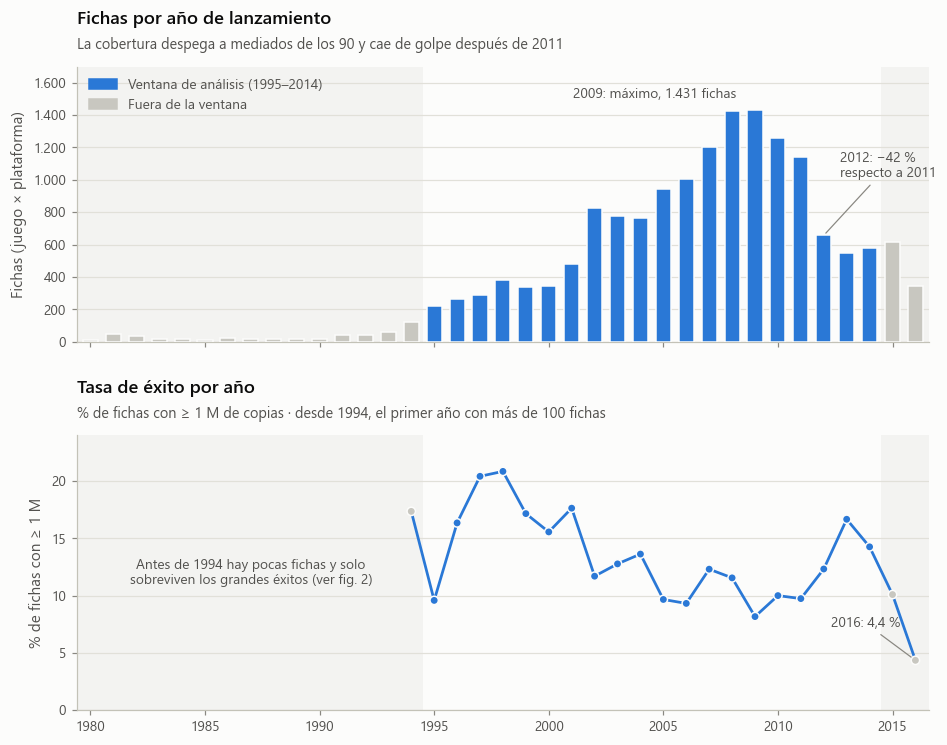

,titulos,tasa_exito,mediana
anio,,,
2008,1428,0.116,0.17
2011,1139,0.097,0.14
2012,657,0.123,0.17
2014,582,0.143,0.16
2015,614,0.101,0.09
2016,344,0.044,0.05


In [7]:
anios = np.arange(1980, 2017)
tabla = (df.assign(exito=df["ventas_global"] >= 1)
           .groupby("anio")
           .agg(titulos=("nombre", "size"), tasa_exito=("exito", "mean"), mediana=("ventas_global", "median")))
tabla.index = tabla.index.astype(int)
tabla = tabla.reindex(anios)
dentro = (anios >= L.VENTANA_INICIO) & (anios <= L.VENTANA_FIN)
colores = np.where(dentro, estilo.AZUL, estilo.GRIS_FONDO)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7.6), sharex=True, gridspec_kw={"hspace": 0.34})

# --- panel 1: fichas por año
ax1.bar(anios, tabla["titulos"], width=0.66, color=colores, edgecolor=estilo.SUPERFICIE, linewidth=1.0, zorder=3)
estilo.titular(ax1, "Fichas por año de lanzamiento", "La cobertura despega a mediados de los 90 y cae de golpe después de 2011")
ax1.set_ylabel("Fichas (juego × plataforma)")
ax1.set_ylim(0, 1700)
ax1.yaxis.set_major_formatter(estilo.formato_eje())
pico = int(tabla["titulos"].idxmax())
ax1.annotate(f"{pico}: máximo, {estilo.num(tabla.loc[pico, 'titulos'])} fichas", (pico, tabla.loc[pico, "titulos"]),
             xytext=(-12, 6), textcoords="offset points", ha="right", va="bottom", fontsize=9, color=estilo.TINTA_2)
caida = (tabla.loc[2012, "titulos"] / tabla.loc[2011, "titulos"] - 1) * 100
ax1.annotate(f"2012: {estilo.pct(caida, 0)}\nrespecto a 2011", (2012, tabla.loc[2012, "titulos"]),
             xytext=(2012.7, 1000), textcoords="data", ha="left", va="bottom", fontsize=9, color=estilo.TINTA_2,
             arrowprops=dict(arrowstyle="-", color=estilo.APAGADO, lw=0.8))
ax1.legend(handles=[Patch(color=estilo.AZUL, label=f"Ventana de análisis ({L.VENTANA_INICIO}–{L.VENTANA_FIN})"),
                    Patch(color=estilo.GRIS_FONDO, label="Fuera de la ventana")], loc="upper left", frameon=False)

# --- panel 2: tasa de éxito por año (desde 1994, el primer año con >= 100 fichas)
tasa = tabla["tasa_exito"].where(anios >= 1994) * 100
ax2.plot(anios, tasa, color=estilo.AZUL, lw=1.8, zorder=3)
ax2.scatter(anios, tasa, s=30, color=colores, edgecolor=estilo.SUPERFICIE, linewidth=1.0, zorder=4)
estilo.titular(ax2, "Tasa de éxito por año", "% de fichas con ≥ 1 M de copias · desde 1994, el primer año con más de 100 fichas")
ax2.set_ylabel("% de fichas con ≥ 1 M")
ax2.set_ylim(0, 24)
ax2.yaxis.set_major_formatter(estilo.formato_eje())
ax2.annotate(f"2016: {estilo.pct(tasa[2016])}", (2016, tasa[2016]), xytext=(-10, 22), textcoords="offset points", ha="right",
             fontsize=9, color=estilo.TINTA_2, arrowprops=dict(arrowstyle="-", color=estilo.APAGADO, lw=0.8))
ax2.text(1987, 12, "Antes de 1994 hay pocas fichas y solo\nsobreviven los grandes éxitos (ver fig. 2)",
         ha="center", va="center", fontsize=9, color=estilo.TINTA_2)

for ax in (ax1, ax2):
    ax.axvspan(1979.4, L.VENTANA_INICIO - 0.5, color=estilo.GRIS_FONDO, alpha=0.16, lw=0, zorder=0)
    ax.axvspan(L.VENTANA_FIN + 0.5, 2016.6, color=estilo.GRIS_FONDO, alpha=0.16, lw=0, zorder=0)
    ax.set_xlim(1979.4, 2016.6)
ax2.set_xticks(range(1980, 2017, 5))
estilo.guardar(fig, "fig01_cobertura_por_anio.png")
plt.show()

tabla.loc[[2008, 2011, 2012, 2014, 2015, 2016]].round(3)

> **Hallazgo.** Tras 2011 el número de fichas cae un 42 % de golpe (de ~1.140 a ~660) y 2016 llega a medias (344 fichas, con solo un 4,4 % de éxitos). Con estos datos **no se puede distinguir** entre una caída real de lanzamientos y un cambio en lo que el *scraper* alcanza a registrar; lo prudente es no leer esa caída como una señal del mercado.
>
> Además, las ventas de un título se acumulan con los años: los lanzamientos de 2015–2016 tuvieron poco tiempo para sumar copias dentro de lo que registra el dataset (la mediana de 2015 es de 0,09 M, por debajo de todo el rango 0,11–0,19 M de 2005–2014). Es un caso de **censura por la derecha**.

### 3.3 Sesgo de supervivencia en las plataformas antiguas
Las plataformas de los 80 y principios de los 90 tienen muy pocas fichas. ¿Qué pasa con su tasa de éxito?

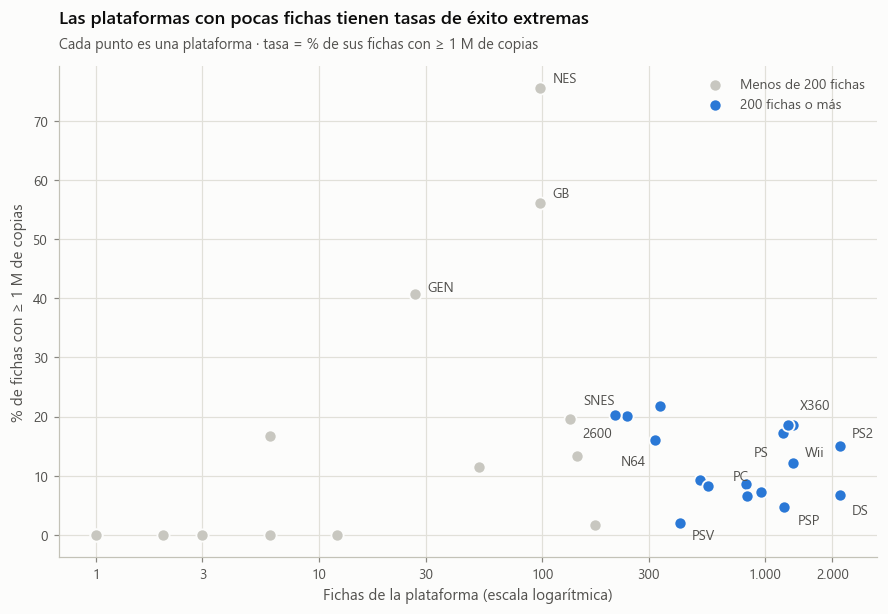

,fichas,tasa
plataforma,,
NES,98,75.5
GB,98,56.1
GEN,27,40.7
PS4,336,21.7
XOne,213,20.2
SNES,239,20.1
2600,133,19.5
X360,1265,18.7


In [8]:
plat = (df.assign(exito=df["ventas_global"] >= 1)
          .groupby("plataforma")
          .agg(fichas=("exito", "size"), tasa=("exito", "mean"))
          .assign(tasa=lambda t: t["tasa"] * 100))
grandes = plat["fichas"] >= 200

fig, ax = plt.subplots(figsize=(9.6, 5.8))
ax.scatter(plat.loc[~grandes, "fichas"], plat.loc[~grandes, "tasa"], s=64, color=estilo.GRIS_FONDO,
           edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=3, label="Menos de 200 fichas")
ax.scatter(plat.loc[grandes, "fichas"], plat.loc[grandes, "tasa"], s=64, color=estilo.AZUL,
           edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=3, label="200 fichas o más")
ax.set_xscale("log")
ax.set_xticks([1, 3, 10, 30, 100, 300, 1000, 2000], ["1", "3", "10", "30", "100", "300", "1.000", "2.000"])
ax.minorticks_off()
estilo.rejilla(ax, "ambos")
estilo.titular(ax, "Las plataformas con pocas fichas tienen tasas de éxito extremas",
               "Cada punto es una plataforma · tasa = % de sus fichas con ≥ 1 M de copias")
ax.set_xlabel("Fichas de la plataforma (escala logarítmica)")
ax.set_ylabel("% de fichas con ≥ 1 M de copias")
ax.yaxis.set_major_formatter(estilo.formato_eje())
desplazamiento = {"NES": (8, 4), "GB": (8, 4), "GEN": (8, 2), "2600": (8, -12), "SNES": (-8, 8), "N64": (-6, -16), "PS": (-9, -15),
                  "PS2": (8, 6), "DS": (8, -12), "PSP": (9, -11), "PSV": (8, -10), "PC": (-8, 8), "X360": (8, 10), "Wii": (8, 4)}
for nombre, (dx, dy) in desplazamiento.items():
    x, y = plat.loc[nombre, ["fichas", "tasa"]]
    ax.annotate(nombre, (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=9, color=estilo.TINTA_2,
                ha="left" if dx > 0 else "right")
ax.legend(loc="upper right", frameon=False)
estilo.guardar(fig, "fig02_sesgo_supervivencia_plataformas.png")
plt.show()

plat.sort_values("tasa", ascending=False).head(8).round(1)

> **Hallazgo.** NES y Game Boy parecen «las plataformas con más éxitos» (más de la mitad de sus fichas supera el millón), pero cada una tiene unas cien fichas: el dataset solo conserva los pocos juegos de entonces que dejaron huella. Es **sesgo de supervivencia**, no una propiedad de esas consolas. Comparar su tasa con la de PS2 (más de 2.000 fichas) sería comparar cosas distintas.
>
> **Decisión: ventana de análisis 1995–2014** (`en_ventana`). Se descarta antes de 1995 por la poca cobertura y el sesgo de supervivencia, y 2015–2016 por la censura por la derecha y el año incompleto. Es una regla conservadora, fijada **antes** de modelar; el notebook 03 la pone a prueba con 2015 y 2016.

## 4. Duplicados: tres casos que parecen lo mismo y no lo son
La receta habitual, `drop_duplicates(["nombre", "plataforma"])`, ¿es segura aquí?

In [9]:
mismo_nombre = df[df.duplicated(["nombre", "plataforma"], keep=False)].sort_values(["nombre", "plataforma", "anio"])
mismo_nombre[["rank_original", "nombre", "plataforma", "anio", "publisher", "ventas_na", "ventas_eu", "ventas_global"]]

,rank_original,nombre,plataforma,anio,publisher,ventas_na,ventas_eu,ventas_global
603,604,Madden NFL 13,PS3,2012,Electronic Arts,2.11,0.23,2.56
16127,16130,Madden NFL 13,PS3,2012,Electronic Arts,0.00,0.01,0.01
5900,5902,Need for Speed: Most Wanted,PC,2005,Electronic Arts,0.02,0.23,0.30
11676,11678,Need for Speed: Most Wanted,PC,2012,Electronic Arts,0.00,0.06,0.08
1530,1532,Need for Speed: Most Wanted,X360,2005,Electronic Arts,1.00,0.17,1.29
1173,1175,Need for Speed: Most Wanted,X360,2012,Electronic Arts,0.62,0.80,1.58
1715,1717,Sonic the Hedgehog,PS3,2006,Sega,0.41,0.07,1.18
4145,4147,Sonic the Hedgehog,PS3,<NA>,NaN,0.00,0.48,0.48
14997,15000,Wii de Asobu: Metroid Prime,Wii,<NA>,Nintendo,0.00,0.00,0.02
14999,15002,Wii de Asobu: Metroid Prime,Wii,<NA>,Nintendo,0.00,0.00,0.02


| Caso | Filas | Veredicto | Decisión |
|---|---|---|---|
| *Wii de Asobu: Metroid Prime* (Wii) | 2 | Idénticas salvo `rank_original` | Se elimina una |
| *Madden NFL 13* (PS3, 2012) | 2 | Misma ficha: una con 2,56 M y otra «fantasma» con 0,01 M | Se conserva la de mayores ventas |
| *Need for Speed: Most Wanted* (PC y X360) | 4 | **2005 y 2012 son dos juegos distintos** con el mismo título | Se conservan |
| *Sonic the Hedgehog* (PS3) | 2 | Una de 2006 y otra sin año ni editora, solo con ventas europeas: ambiguo | Se conserva y se documenta |

El `drop_duplicates` ingenuo habría borrado un juego legítimo de cada pareja de *Most Wanted* y la ficha ambigua de *Sonic*.

In [10]:
ingenuo = df.drop_duplicates(["nombre", "plataforma"])
df, info_dup = L.quitar_duplicados(df)
print(f"drop_duplicates(['nombre', 'plataforma']) eliminaría {len(crudo) - len(ingenuo)} filas; la limpieza correcta elimina {info_dup['filas_antes'] - info_dup['filas_despues']}.")
info_dup["eliminadas"]

drop_duplicates(['nombre', 'plataforma']) eliminaría 5 filas; la limpieza correcta elimina 2.


,rank_original,nombre,plataforma,anio,ventas_global
14999,15002,Wii de Asobu: Metroid Prime,Wii,<NA>,0.02
16127,16130,Madden NFL 13,PS3,2012,0.01


> **Decisión.** Se eliminan 2 filas (de 16.598 a 16.596). Regla: *idénticas salvo el rank* o *misma (nombre, plataforma, año)* → se conserva la de mayores ventas. Los homónimos con años distintos **no** son duplicados.

## 5. Registros parciales: la fuente de la cifra viene escrita en el nombre
Algunos nombres traen anotaciones como `(JP sales)`, `(US weekly sales)` o `(All region sales)`. Son fichas cuya cifra proviene de una fuente concreta, no del total del juego.

In [11]:
df, info_par = L.marcar_registros_parciales(df)
print(f"Fichas con la fuente anotada en el nombre: {info_par['n_parciales']}")
print(f"  · con una ficha «normal» del mismo juego en la misma plataforma (doble conteo): {info_par['n_con_ficha_base']}")
print(f"  · sin ficha normal (único registro de ese juego): {info_par['n_sin_ficha_base']}")
print(f"  · ventas que suman: {info_par['ventas_global_parciales']:.1f} M de {info_par['ventas_global_total']:,.0f} M ({info_par['ventas_global_parciales'] / info_par['ventas_global_total']:.2%})\n")

# un caso con ficha normal + dos parciales, y otro donde solo existen las parciales
yugioh = df["nombre"].str.startswith("Yu-Gi-Oh! The Sacred Cards") & df["plataforma"].eq("GBA")
tony_hawk = df["nombre"].str.startswith("Tony Hawk's American Wasteland") & df["plataforma"].eq("PS2")
df.loc[yugioh | tony_hawk, ["nombre", "plataforma", "anio", "ventas_na", "ventas_eu", "ventas_jp", "ventas_otros",
                            "ventas_global", "registro_parcial"]]

Fichas con la fuente anotada en el nombre: 151
  · con una ficha «normal» del mismo juego en la misma plataforma (doble conteo): 82
  · sin ficha normal (único registro de ese juego): 69
  · ventas que suman: 40.3 M de 8,920 M (0.45%)



,nombre,plataforma,anio,ventas_na,ventas_eu,ventas_jp,ventas_otros,ventas_global,registro_parcial
1134,Tony Hawk's American Wasteland (Old all region...,PS2,2005,0.80,0.63,0.01,0.19,1.62,True
1330,Tony Hawk's American Wasteland (Weekly america...,PS2,2005,1.38,0.05,0.00,0.02,1.45,True
1514,Yu-Gi-Oh! The Sacred Cards,GBA,2002,0.94,0.35,0.00,0.02,1.30,False
1752,Yu-Gi-Oh! The Sacred Cards (American and Other...,GBA,2002,0.84,0.27,0.00,0.05,1.16,True
6330,Yu-Gi-Oh! The Sacred Cards (JP weekly sales),GBA,2002,0.00,0.00,0.26,0.01,0.27,True


> **Hallazgo.** *Yu-Gi-Oh! The Sacred Cards* (GBA) aparece **tres veces**: la ficha normal (1,30 M), una de «American and Others sales» (1,16 M) y otra de «JP weekly sales» (0,27 M). Describen el mismo juego con cifras que se solapan (América y Europa figuran en dos fichas con valores distintos) y que no se pueden reconciliar sin saber de dónde sale cada una. En el otro extremo, *Tony Hawk's American Wasteland* en PS2 **solo** existe en versiones anotadas: su cifra describe lo que midió una fuente concreta, no el total del juego.
>
> **Decisión.** Se marcan con `registro_parcial` (151 fichas, el 0,9 % de las filas y solo el 0,45 % de las ventas) y **se excluyen de los análisis por título**. No se borran: el archivo limpio conserva el registro completo.

## 6. Ventas: qué significa cada columna

### 6.1 `Global_Sales` no es información nueva

In [12]:
suma_regional = df[L.VENTAS_REGIONALES].sum(axis=1)
dif = (df["ventas_global"] - suma_regional).round(2)
print(f"ventas_global − (NA + EU + JP + Otros):  mín {dif.min():+.2f} · máx {dif.max():+.2f} · exactamente 0 en el {(dif == 0).mean():.1%} de las fichas")
print(f"Fichas con |diferencia| mayor que 0,02 (el máximo posible por redondeo): {(dif.abs() > 0.02).sum()}")

ventas_global − (NA + EU + JP + Otros):  mín -0.02 · máx +0.02 · exactamente 0 en el 72.8% de las fichas
Fichas con |diferencia| mayor que 0,02 (el máximo posible por redondeo): 0


> **Hallazgo.** `Global_Sales` es la **suma de las cuatro regiones** (la diferencia máxima, ±0,02, es puro redondeo a centésimas). Y el objetivo del proyecto, «vender ≥ 1 M», se define con esa columna. Un modelo que use las ventas regionales como predictores «acierta» casi el 100 % sin aprender nada: es la fuga de información más típica de este dataset (se demuestra en el notebook 03).

### 6.2 Granularidad y ceros

In [13]:
ceros = (df[L.VENTAS_REGIONALES] == 0).mean().mul(100).round(1)
print("% de fichas con 0,00 por región:", ceros.to_dict())
minimo = df["ventas_global"].min()
print(f"\nVentas globales mínimas: {minimo} M ({minimo * 1e6:,.0f} copias) en {(df['ventas_global'] == minimo).sum()} fichas "
      f"({(df['ventas_global'] == minimo).mean():.1%}); fichas por debajo de 100.000 copias: {(df['ventas_global'] < 0.1).mean():.1%}")

% de fichas con 0,00 por región: {'ventas_na': 27.1, 'ventas_eu': 34.5, 'ventas_jp': 63.0, 'ventas_otros': 39.0}

Ventas globales mínimas: 0.01 M (10,000 copias) en 617 fichas (3.7%); fichas por debajo de 100.000 copias: 34.8%


> **Hallazgo 1.** Las cifras vienen redondeadas a **0,01 M (10.000 copias)**. Un `0.00` regional significa «menos de ~5.000 copias *o* no se lanzó allí»; no es posible distinguirlo. En Japón, por ejemplo, casi dos de cada tres fichas tienen cero: tratarlo como «ventas nulas» sería un error de interpretación.
>
> **Hallazgo 2.** La descripción pública habla de títulos «con más de 100.000 copias», pero **una de cada tres fichas (34,8 %) vende menos que eso** y 617 tienen justo 0,01 M (10.000 copias). El archivo no cumple su propia descripción. No cambia nada de lo que sigue, pero es un buen motivo para no tomar la documentación al pie de la letra.

### 6.3 `Rank` es el objetivo con otro nombre

In [14]:
orden = crudo.sort_values("Rank")
ordena_por_ventas = (orden["Global_Sales"].diff().dropna() <= 1e-9).all()
faltan = sorted(set(range(1, int(crudo["Rank"].max()) + 1)) - set(crudo["Rank"]))
print("Rank ordena las fichas por Global_Sales de mayor a menor:", ordena_por_ventas)
print(f"Rank llega a {crudo['Rank'].max():,} pero hay {len(crudo):,} filas. Posiciones que faltan: {faltan}")

Rank ordena las fichas por Global_Sales de mayor a menor: True
Rank llega a 16,600 pero hay 16,598 filas. Posiciones que faltan: [654, 14200]


> **Hallazgo.** `Rank` es una función monótona de `Global_Sales`: usarlo como variable explicativa equivale a regalarle la respuesta al modelo. Sus dos huecos (654 y 14200) cuadran con las dos fichas que, según las descripciones públicas del dataset, se descartaron por estar incompletas.
>
> **Decisión.** `rank_original` se conserva solo como referencia y **nunca** entra como predictor.

## 7. Un mismo juego, varias fichas
Como cada fila es *juego × plataforma*, el mismo título se repite. ¿Cuánto?

In [15]:
fichas_por_nombre = df.groupby("nombre")["nombre"].transform("size")
multi = df[fichas_por_nombre > 1]
print(f"Nombres únicos: {df['nombre'].nunique():,} · fichas: {len(df):,}")
print(f"Nombres con más de una ficha: {multi['nombre'].nunique():,} → {len(multi):,} fichas ({len(multi) / len(df):.1%} del total)")
print(f"Máximo de fichas de un mismo nombre: {fichas_por_nombre.max()} ({df.loc[fichas_por_nombre.idxmax(), 'nombre']})\n")

pd.DataFrame({"nombres afectados": [
    (multi.groupby("nombre")["genero"].nunique() > 1).sum(),
    (multi.groupby("nombre")["publisher"].nunique() > 1).sum(),
    (multi.groupby("nombre")["anio"].nunique() > 1).sum()]},
    index=["género distinto entre plataformas", "publisher distinto entre plataformas", "año distinto entre plataformas"])

Nombres únicos: 11,493 · fichas: 16,596
Nombres con más de una ficha: 2,774 → 7,877 fichas (47.5% del total)
Máximo de fichas de un mismo nombre: 12 (Need for Speed: Most Wanted)



,nombres afectados
género distinto entre plataformas,4
publisher distinto entre plataformas,332
año distinto entre plataformas,694


> **Hallazgo.** Casi la mitad de las fichas pertenecen a juegos que salieron en más de una plataforma, y esas versiones se parecen mucho entre sí (mismo género, casi siempre la misma editora, ventas del mismo orden). El género es consistente entre plataformas; la editora y el año, no tanto (ports tardíos, editoras regionales).
>
> **Consecuencias para el modelado** (notebook 03):
> 1. Un *split* aleatorio filtra información: la versión de PS3 caería en entrenamiento y la de Xbox 360 en prueba. La validación debe respetar el tiempo y, donde sea posible, agrupar por título.
> 2. «En cuántas plataformas sale a la vez» es una variable de negocio por sí misma (`n_versiones`).
> 3. Para hablar de *franquicias* hay que derivarlas del nombre (`franquicia`, ver sección 9).

## 8. Inventario de problemas

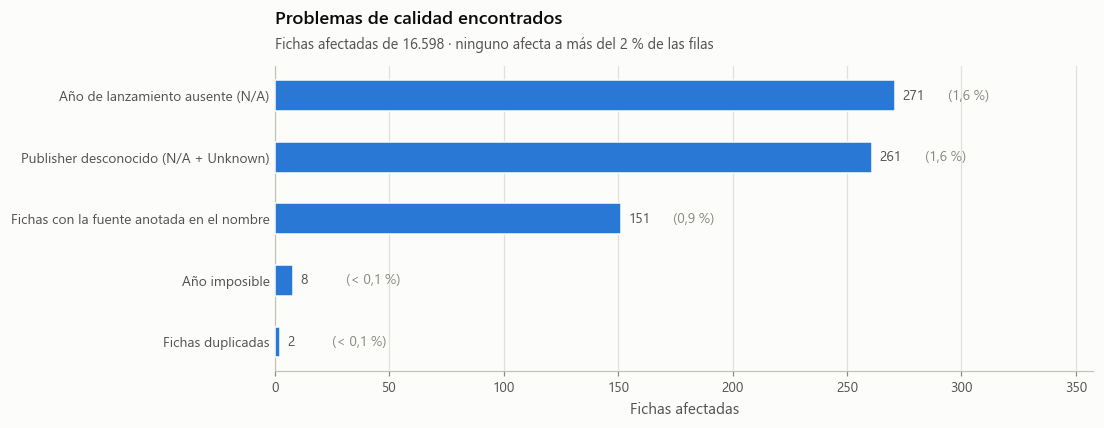

In [16]:
inventario = pd.Series({
    "Año de lanzamiento ausente (N/A)": info_anios["n_nulos_originales"],
    "Publisher desconocido (N/A + Unknown)": info_pub["n_total"],
    "Fichas con la fuente anotada en el nombre": info_par["n_parciales"],
    "Año imposible": info_anios["n_futuro"] + info_anios["n_previo_a_consola"],
    "Fichas duplicadas": info_dup["n_identicas"] + info_dup["n_fantasma"],
}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9.6, 3.6))
y = estilo.barras_h(ax, inventario.index, inventario.values, alto=0.5)
for yi, v in zip(y, inventario.values):                       # el % de filas, junto al conteo
    porcentaje = v / len(crudo) * 100
    etiqueta = "(< 0,1 %)" if porcentaje < 0.1 else f"({estilo.pct(porcentaje)})"
    ax.text(v + inventario.max() * 0.085, yi, etiqueta, va="center", ha="left", fontsize=9, color=estilo.APAGADO)
ax.set_xlim(0, inventario.max() * 1.32)
estilo.titular(ax, "Problemas de calidad encontrados", f"Fichas afectadas de {estilo.num(len(crudo))} · ninguno afecta a más del 2 % de las filas")
ax.set_xlabel("Fichas afectadas")
estilo.guardar(fig, "fig03_inventario_problemas.png")
plt.show()

Los defectos son pocos y pequeños; lo que más pesa en este dataset no son los errores sino **cómo está construido** (fichas por plataforma, cifras estimadas y redondeadas, cobertura cambiante, `Global_Sales` ≡ suma regional, `Rank` ≡ objetivo). Esas «trampas de diseño» son las que invalidan un modelo ingenuo.

## 9. Dataset limpio y verificación
Se añaden las columnas derivadas y se comprueba que aplicar los pasos uno a uno da exactamente lo mismo que el pipeline completo (`L.limpiar`), que es el que se usará en los demás notebooks.

| Columna derivada | Qué es |
|---|---|
| `fabricante`, `tipo_plataforma` | Nintendo / Sony / Microsoft / Sega / PC / Otros · Sobremesa / Portátil / PC |
| `edad_plataforma` | Años desde el lanzamiento de la consola (nulo para PC) |
| `franquicia` | Clave heurística de la saga, a partir del nombre (ver abajo) |
| `exito` | 1 si `ventas_global` ≥ 1 M de copias |
| `en_ventana` | Año entre 1995 y 2014 |

In [17]:
df = L.agregar_derivadas(df)
limpio, registro = L.limpiar(CRUDO)
pd.testing.assert_frame_equal(limpio, df[L.ORDEN_COLUMNAS])
print("✔ los pasos aplicados uno a uno coinciden con el pipeline completo\n")

resultados = L.validar(limpio)
for descripcion, ok in resultados:
    print("✔" if ok else "✘", descripcion)
assert all(ok for _, ok in resultados)
print(f"\n{len(resultados)}/{len(resultados)} verificaciones en verde")

✔ los pasos aplicados uno a uno coinciden con el pipeline completo

✔ no quedan filas identicas (ignorando rank)
✔ no quedan (nombre, plataforma, anio) repetidos
✔ rank_original es unico
✔ ninguna venta negativa
✔ ventas_global >= 0.01 en todas las filas
✔ ventas_global = suma regional +/- 0.02 (redondeo)
✔ ventas_global >= cada venta regional
✔ anio dentro de 1980-2016 o nulo
✔ ningun anio anterior al lanzamiento de la consola
✔ 'Unknown' ya no existe como publisher
✔ publisher_desconocido coincide con publisher nulo
✔ 12 generos y 31 plataformas, sin nulos
✔ toda plataforma tiene fabricante
✔ exito == (ventas_global >= 1)
✔ las 3 banderas son booleanas
✔ en_ventana implica anio conocido en 1995-2014
✔ edad_plataforma >= 0 cuando existe
✔ franquicia no vacia salvo casos extremos (<0.5%)

18/18 verificaciones en verde


### La columna `franquicia`: una heurística, con sus límites
Las sagas no vienen en el dataset. Se derivan del nombre quitando entregas, años, plataformas y anotaciones (`extraer_franquicia`). Sirve para las sagas de nombre estable y falla en las que cambian de nombre por edición:

In [18]:
ejemplos = ["Call of Duty: Black Ops II", "FIFA 14", "FIFA Soccer 13", "Madden NFL 13", "Mario Kart Wii", "Grand Theft Auto V",
            "Pokemon Red/Pokemon Blue", "Pokemon Gold/Pokemon Silver", "New Super Mario Bros. Wii", "Super Mario Bros. 3"]
pd.DataFrame({"nombre": ejemplos, "franquicia": [L.extraer_franquicia(n) for n in ejemplos]})

,nombre,franquicia
0,Call of Duty: Black Ops II,call of duty
1,FIFA 14,fifa
2,FIFA Soccer 13,fifa
3,Madden NFL 13,madden nfl
4,Mario Kart Wii,mario kart
5,Grand Theft Auto V,grand theft auto
6,Pokemon Red/Pokemon Blue,pokemon red
7,Pokemon Gold/Pokemon Silver,pokemon gold
8,New Super Mario Bros. Wii,new super mario bros
9,Super Mario Bros. 3,super mario bros


> Las cuatro primeras sagas se agrupan bien (*FIFA* con y sin «Soccer» converge). Pero cada edición de *Pokémon* queda como una saga distinta y la familia *Mario* se fragmenta en varias claves. Es una limitación asumida: el notebook 03 mide cuánto cuesta y la lista de errores del modelo la vuelve a mencionar. Mejorarla (diccionario o *fuzzy matching*) sería un siguiente paso.

### Guardado

In [19]:
limpio.to_csv(L.PROCESSED, index=False)
print(f"Guardado: {L.PROCESSED.relative_to(RAIZ)}  ({limpio.shape[0]:,} filas × {limpio.shape[1]} columnas)")
print("\nFichas marcadas por cada bandera:")
print(limpio[["publisher_desconocido", "anio_invalido", "registro_parcial", "en_ventana"]].sum().to_string())
print(f"\nFichas utilizables para el análisis por título (sin parciales, año conocido, en ventana): "
      f"{int((~limpio['registro_parcial'] & limpio['en_ventana']).sum()):,}")
limpio.dtypes.to_frame("tipo").T

Guardado: data\processed\vgsales_clean.csv  (16,596 filas × 20 columnas)

Fichas marcadas por cada bandera:
publisher_desconocido      261
anio_invalido                8
registro_parcial           151
en_ventana               14876

Fichas utilizables para el análisis por título (sin parciales, año conocido, en ventana): 14,734


,rank_original,nombre,plataforma,anio,genero,publisher,ventas_na,ventas_eu,ventas_jp,ventas_otros,ventas_global,fabricante,tipo_plataforma,edad_plataforma,franquicia,exito,en_ventana,publisher_desconocido,anio_invalido,registro_parcial
tipo,int64,str,str,Int64,str,str,float64,float64,float64,float64,float64,str,str,Float64,str,int64,bool,bool,bool,bool


## 10. Resumen de decisiones

| Problema | Fichas | Decisión | Por qué |
|---|---|---|---|
| Publisher `Unknown` (+ `N/A`) | 261 | Nulo + bandera `publisher_desconocido`; no se imputa | Nulo disfrazado; falta de forma no aleatoria y es informativo |
| Años imposibles | 8 | Nulo + bandera `anio_invalido` | No hay forma de saber el año correcto |
| Año ausente | 271 | Se mantiene nulo | Se excluyen solo de los análisis por año |
| Duplicados reales | 2 | Se eliminan | Son la misma ficha |
| Homónimos (*Most Wanted*) | 4 | Se conservan | Son juegos distintos |
| Fichas con fuente anotada | 151 | Bandera `registro_parcial`; fuera de los análisis | Duplican o subestiman |
| Cobertura y madurez | — | Ventana 1995–2014 (`en_ventana`) | Sesgo de supervivencia, caída de cobertura, censura por la derecha |
| `Global_Sales` ≡ suma regional | — | No usar las regionales para predecir el éxito | Fuga de información |
| `Rank` ≡ función de `Global_Sales` | — | No usar como predictor | Es el objetivo con otro nombre |
| Un juego, varias fichas | 7.877 | Validar respetando el tiempo; variable `n_versiones` | Evitar que las fichas «hermanas» crucen entrenamiento y prueba |

**Siguiente:** [02 · Análisis exploratorio](02_analisis_exploratorio.ipynb).